In [1]:
# Módulos numéricos y de funciones científicas
import numpy as np
from scipy import signal as sig
import sympy as sp
from IPython.display import display, Math

# Módulos para los gráficos
import matplotlib as mpl
from matplotlib import pyplot as plt

# Funciones de PyTC2
from pytc2.sistemas_lineales import bodePlot, pzmap, GroupDelay, analyze_sys, tf2sos_analog, pretty_print_SOS, plot_plantilla
from pytc2.general import print_latex, print_subtitle, a_equal_b_latex_s

#Tamaño de los gráficos
fig_sz_x = 13
fig_sz_y = 7
fig_dpi = 80 # dpi

fig_font_size = 11

mpl.rcParams['figure.figsize'] = (fig_sz_x, fig_sz_y)
mpl.rcParams['figure.dpi'] = fig_dpi
plt.rcParams.update({'font.size':fig_font_size})

#### **Pasabajos usando TransferFunction**

[1.02444900e-05 5.12224498e-05 1.02444900e-04 1.02444900e-04
 5.12224498e-05 1.02444900e-05]
[ 1.         -4.5878723   8.53992135 -8.05601007  3.84945626 -0.74516742]


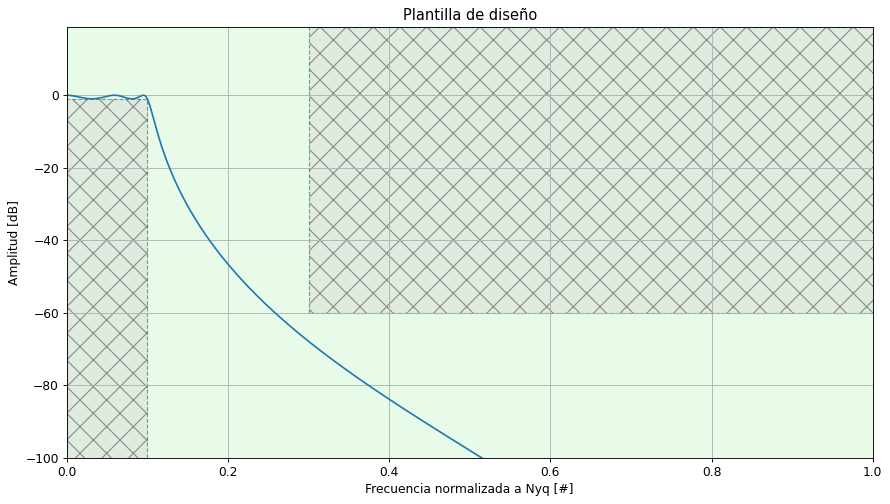

In [52]:
fpass = 100
fstop = 300
atte = 60
ripple = 1
fs=2000
fN = fs/2
npoints = 1000

wpass = fpass/fN
wstop = fstop/fN

num , den = sig.iirdesign( wpass, wstop, ripple, atte, ftype = "cheby1")

print(num)
print(den)

filtro = sig.TransferFunction(num,den, dt=1/fs)
w, mod, _ = filtro.bode(npoints)


w_nyq = 2*np.pi*fN

plt.figure()
plt.plot(w/w_nyq, mod)
plt.title('Plantilla de diseño')
plt.xlabel('Frecuencia normalizada a Nyq [#]')
plt.ylabel('Amplitud [dB]')
plt.grid(which='both', axis='both')

plt.gca().set_xlim([0,1])
plot_plantilla( filter_type='lowpass', fpass=fpass/fN, ripple=ripple, fstop=fstop/fN, attenuation=atte, fs=fs )

#### **Pasabajos usando freqz**

[1.02444900e-05 5.12224498e-05 1.02444900e-04 1.02444900e-04
 5.12224498e-05 1.02444900e-05]
[ 1.         -4.5878723   8.53992135 -8.05601007  3.84945626 -0.74516742]


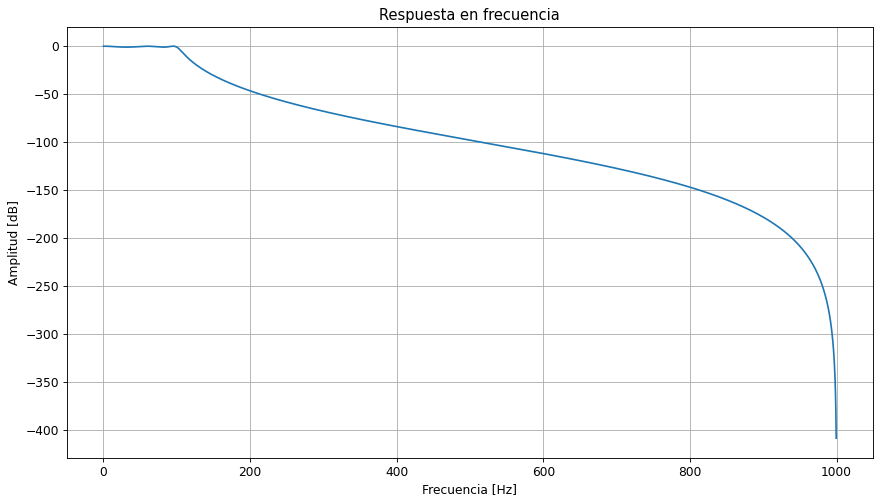

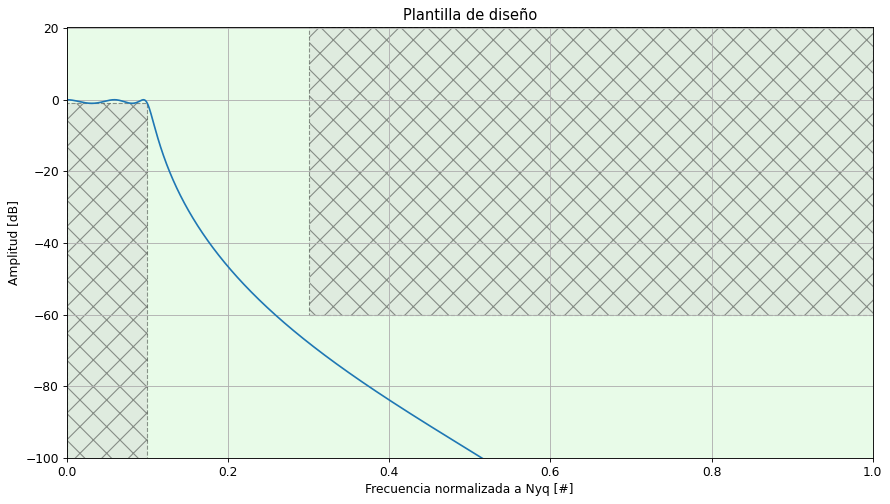

In [58]:
#Variables de Plantilla
fpass = 100
fstop = 300
atte = 60
ripple = 1

#Parametros Digitales
fs=2000
fN = fs/2
npoints = 2000

#Frecuencias normalizadas
#wpass = fpass/fN
#wstop = fstop/fN

#Coeficientes
num , den = sig.iirdesign( fpass, fstop, ripple, atte, ftype = "cheby1", fs=fs)

print(num)
print(den)

#Respuesta en frecuencia
w, h = sig.freqz( num, den, npoints, fs=fs)
modh = 20*np.log10(np.abs(h))

plt.figure()
plt.plot(w, modh)
plt.title('Respuesta en frecuencia')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [dB]')
plt.grid(which='both', axis='both')

plt.figure()
plt.plot(w/fN, modh)
plt.title('Plantilla de diseño')
plt.xlabel('Frecuencia normalizada a Nyq [#]')
plt.ylabel('Amplitud [dB]')
plt.grid(which='both', axis='both')
plt.gca().set_xlim([0,1])
plot_plantilla( filter_type='lowpass', fpass=fpass/fN, ripple=ripple, fstop=fstop/fN, attenuation=atte, fs=fs )

[[ 0.1632309   0.3264618   0.1632309   1.         -0.6344396   0.36703192]]


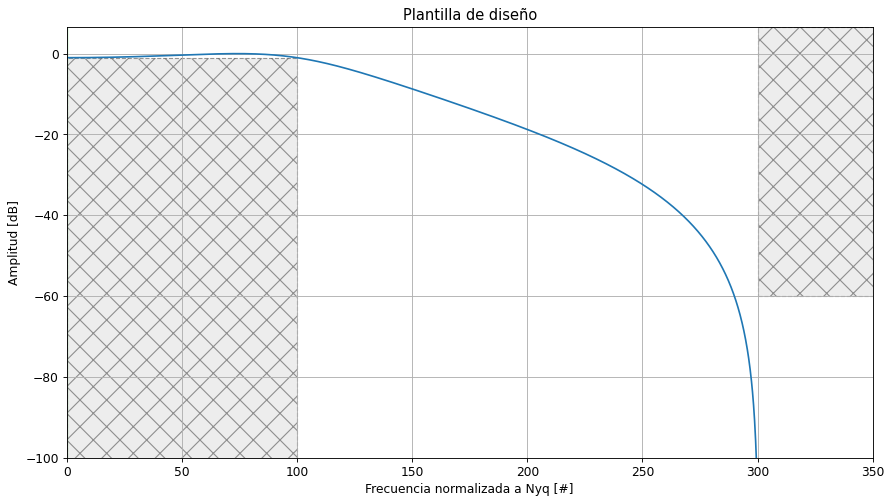

In [14]:
#Variables de Plantilla
fpass = 100
fstop = 300
atte = 60
ripple = 1

#Parametros Digitales
fs=601
fN = fs/2
npoints = 2000

#Coeficientes
#num , den = sig.iirdesign( fpass, fstop, ripple, atte, ftype = "cheby1", fs=fs)
sos = sig.iirdesign( fpass, fstop, ripple, atte, ftype = "cheby1", fs=fs, output='sos')

print(sos)

#Respuesta en frecuencia
#w, h = sig.freqz( num, den, npoints, fs=fs)
w, h = sig.sosfreqz( sos, npoints, fs=fs)
modh = 20*np.log10(np.abs(h))

plt.figure()
plt.plot(w, modh)
plt.title('Plantilla de diseño')
plt.xlabel('Frecuencia normalizada a Nyq [#]')
plt.ylabel('Amplitud [dB]')
plt.grid(which='both', axis='both')
plt.gca().set_xlim([0,350])
plot_plantilla( filter_type='lowpass', fpass=fpass, ripple=ripple, fstop=fstop, attenuation=atte)

In [17]:
#Variables de Plantilla
fpass = 100
fstop = 300
atte = 60
ripple = 1

#Parametros Digitales
fs=2000
fN = fs/2
npoints = 2000

#Coeficientes
sos = sig.iirdesign( fpass, fstop, ripple, atte, ftype = "cheby1", fs=fs, output='sos', analog=False)

#Respuesta en frecuencia
w, h = sig.sosfreqz( sos, npoints, fs=fs)
modh = 20*np.log10(np.abs(h))

print(sos)

[[ 1.02444900e-05  2.04889799e-05  1.02444900e-05  1.00000000e+00
  -9.12317854e-01  0.00000000e+00]
 [ 1.00000000e+00  2.00000000e+00  1.00000000e+00  1.00000000e+00
  -1.82353736e+00  8.63241045e-01]
 [ 1.00000000e+00  1.00000000e+00  0.00000000e+00  1.00000000e+00
  -1.85201709e+00  9.46184000e-01]]


#### **Filtro Notch**

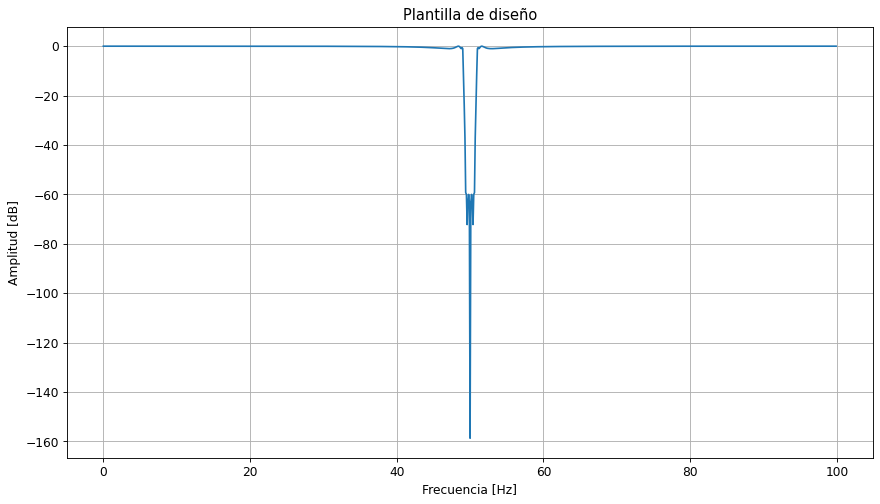

In [25]:
#Parametros Plantilla
fnotch = 50 
bw = 1
ripple = 1
atte = 60

#Parametros Digitales
fs=200
npoints = 1000
fN = fs/2

#Frecuencias de corte
fmin = fnotch - bw/2
fmax = fnotch + bw/2
wmin = fmin/fN
wmax = fmax/fN

#Frecuencias de paso
wpmin = (fmin - bw/2)/fN
wpmax = (fmax + bw/2)/fN
fpmin = (fmin - bw/2)
fpmax = (fmax + bw/2)

#Coeficientes
#num , den = sig.iirdesign( [wpmin ,wpmax ], [wmin, wmax], ripple, atte)
num , den = sig.iirdesign( [fpmin ,fpmax ], [fmin, fmax], ripple, atte, fs=fs)

#Respuesta en frecuencia
w, h = sig.freqz( num, den, npoints, fs=fs)
modh = 20*np.log10(np.abs(h))


plt.plot(w, modh)
plt.title('Plantilla de diseño')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [dB]')
plt.grid(which='both', axis='both')

[[ 8.79854428e-01 -8.59241877e-08  8.79854428e-01  1.00000000e+00
  -8.90602237e-08  8.23934197e-01]
 [ 1.00000000e+00  2.36767687e-02  1.00000000e+00  1.00000000e+00
   8.30889256e-02  9.71190065e-01]
 [ 1.00000000e+00 -2.36769640e-02  1.00000000e+00  1.00000000e+00
  -8.30891177e-02  9.71190065e-01]
 [ 1.00000000e+00  3.61004512e-02  1.00000000e+00  1.00000000e+00
   6.27115510e-02  9.95477591e-01]
 [ 1.00000000e+00 -3.61006465e-02  1.00000000e+00  1.00000000e+00
  -6.27117457e-02  9.95477591e-01]]


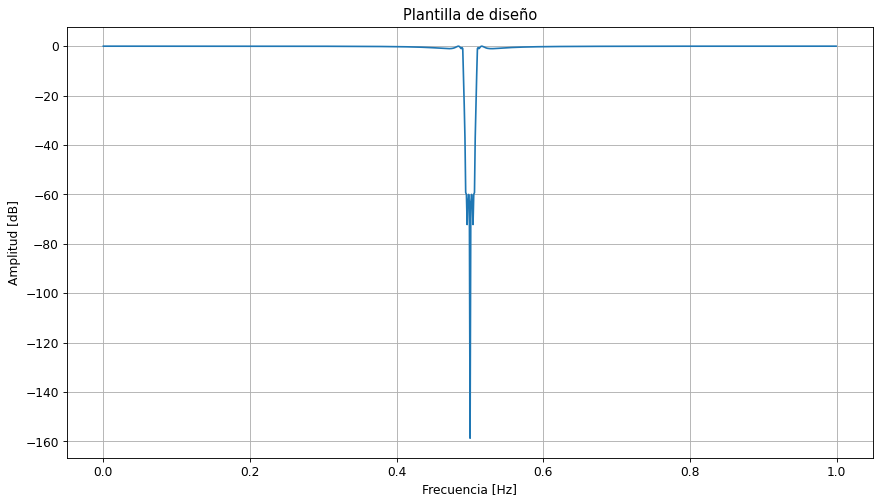

In [20]:
#Parametros Plantilla
fnotch = 50 
bw = 1
ripple = 1
atte = 60

#Parametros Digitales
fs=200
npoints = 1000
fN = fs/2

#Frecuencias de corte
fmin = fnotch - bw/2
fmax = fnotch + bw/2
wmin = fmin/fN
wmax = fmax/fN

#Frecuencias de paso
wpmin = (fmin - bw/2)/fN
wpmax = (fmax + bw/2)/fN
fpmin = (fmin - bw/2)
fpmax = (fmax + bw/2)

#Coeficientes
#num , den = sig.iirdesign( [wpmin ,wpmax ], [wmin, wmax], ripple, atte)
sos = sig.iirdesign( [fpmin ,fpmax ], [fmin, fmax], ripple, atte, fs=fs, output='sos')
print(sos)

#Respuesta en frecuencia
w, h = sig.sosfreqz( sos, npoints, fs=fs)
modh = 20*np.log10(np.abs(h))


plt.plot(w/fN, modh)
#plt.plot(w, modh)
plt.title('Plantilla de diseño')
plt.xlabel('Frecuencia [Hz]')
#plt.xlabel('Frecuencia normalizada a Nyq [#]')
plt.ylabel('Amplitud [dB]')
plt.grid(which='both', axis='both')